# 03 · Modelling: podiums, finishing order and crash risk

**Setup** (same design as the companion F1 project):

* One row per (race, rider); 19 pre-race features: reconstructed grid, qualifying gap,
  same-weekend sprint result, rolling rider and manufacturer form, circuit history, conditions.
* **Walk-forward validation:** season *Y* is predicted by models trained only on seasons
  before *Y*. The test seasons are 2022–2026. Hyperparameters were chosen on 2019–2021.

| model | output |
|---|---|
| Grid order (baseline) | rank = starting position |
| Logistic regression | podium probability |
| LightGBM classifier | podium probability |
| LightGBM LambdaRank | score that orders the whole field |

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from motogp_analytics import model as m
from motogp_analytics import plots
from motogp_analytics.config import DATA_PROCESSED
from motogp_analytics.features import DNF_FEATURES, FEATURE_LABELS, FEATURES

plots.apply_style()
df = pd.read_parquet(DATA_PROCESSED / "features.parquet")

pred = m.walk_forward(df)
pred.to_parquet(DATA_PROCESSED / "predictions.parquet", index=False)
metrics = m.evaluate(pred)
metrics.to_csv(DATA_PROCESSED / "metrics.csv", index=False)
overall = metrics[metrics["season"] == "All"].drop(columns="season").set_index("model")
overall.style.format({"roc_auc": "{:.3f}", "top3_hit": "{:.1%}", "winner_acc": "{:.1%}",
                      "spearman": "{:.3f}", "log_loss": "{:.3f}", "brier": "{:.4f}"},
                     na_rep="–")

,races,roc_auc,top3_hit,winner_acc,spearman,log_loss,brier
model,,,,,,,
Grid order,101,0.895,53.5%,32.7%,0.502,–,–
Logistic regression,101,0.916,59.1%,38.6%,0.519,0.236,0.0750
LightGBM classifier,101,0.914,57.1%,32.7%,0.515,0.240,0.0758
LightGBM LambdaRank,101,0.905,54.5%,28.7%,0.530,–,–


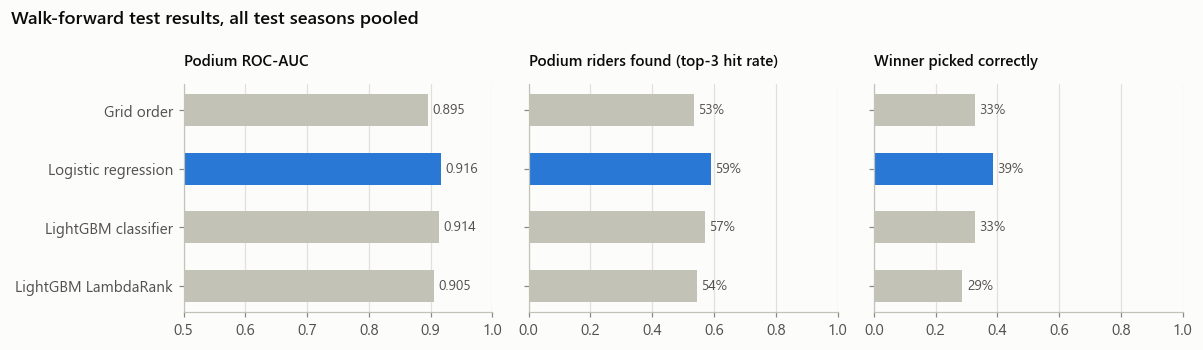

In [2]:
fig = plots.model_comparison(metrics)
plots.save(fig, "model_comparison")
plt.show()

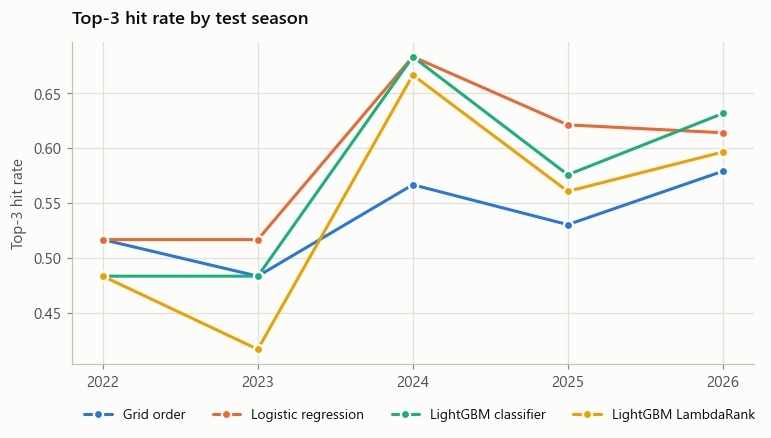

In [3]:
fig = plots.metric_by_season(metrics, "top3_hit", "Top-3 hit rate")
plots.save(fig, "top3_by_season")
plt.show()

In [4]:
metrics.pivot(index="season", columns="model", values="roc_auc").style.format("{:.3f}")

model,Grid order,LightGBM LambdaRank,LightGBM classifier,Logistic regression
season,,,,
2022,0.892,0.890,0.889,0.891
2023,0.883,0.859,0.884,0.890
2024,0.894,0.941,0.945,0.941
2025,0.897,0.915,0.921,0.924
2026,0.911,0.917,0.924,0.928
All,0.895,0.905,0.914,0.916


### Reading the results

In Formula 1, "finish = grid order" is very hard to beat. In MotoGP, **logistic regression
beats the grid baseline on every pooled metric**: podium ROC-AUC 0.916 vs 0.895, top-3 hit rate
59 % vs 54 %, winner accuracy 39 % vs 33 %, and full-order Spearman. The grid says less in
MotoGP, and recent form and the Saturday sprint fill part of the gap.

The gain is not uniform. In 2022–2023 the models only matched the grid, while from 2024 they
are clearly ahead (e.g. AUC 0.945 vs 0.894 in 2024). The simple linear model is as good as
LightGBM here: with about 400 rider-races per season there isn't much non-linear structure to
find.

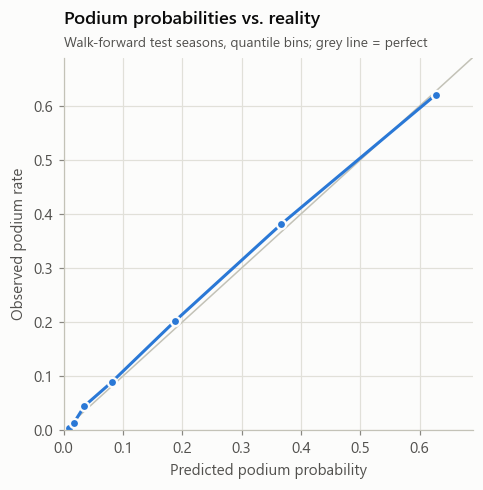

In [5]:
fig = plots.calibration(pred, "p_lgbm", "podium", "Podium probabilities vs. reality")
plots.save(fig, "calibration")
plt.show()

## What drives podium predictions?

Permutation importance: train on 2013–2024, shuffle each feature on 2025–2026 and measure the
drop in ROC-AUC.

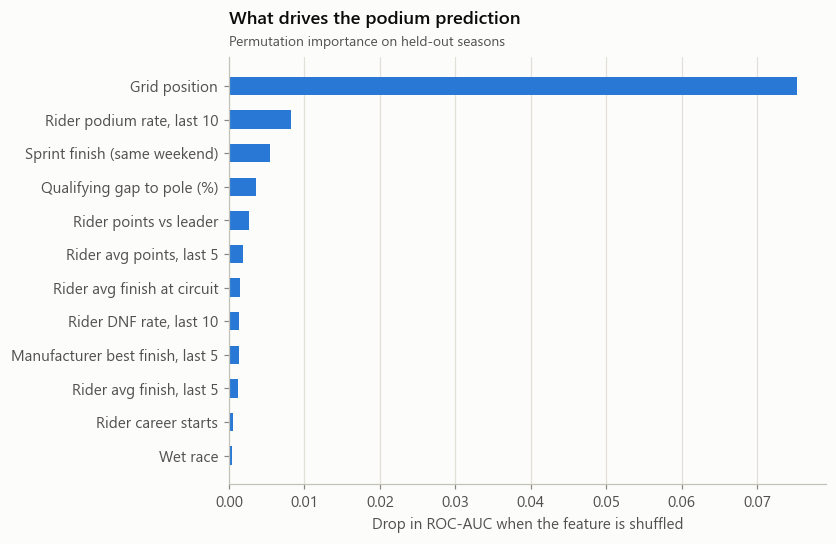

In [6]:
train, hold = df[df["season"] <= 2024], df[df["season"] >= 2025]
clf = m.make_classifier().fit(train[FEATURES], train["podium"])
imp = m.permutation_importance_table(clf, hold[FEATURES], hold["podium"])
imp["label"] = imp["feature"].map(FEATURE_LABELS)
imp.to_csv(DATA_PROCESSED / "importance.csv", index=False)
fig = plots.importance(imp, title="What drives the podium prediction")
plots.save(fig, "feature_importance")
plt.show()

## Crash / DNF risk

Can we tell **before the start** who is likely not to finish? Features: grid slot, qualifying
pace, crashing in the sprint, the rider's and manufacturer's recent DNF rates, the circuit's
DNF history, wet/dry state, temperatures and humidity. DNFs are about 19 % of starts, so we
use **PR-AUC** (average precision). Its no-skill level equals the base rate.

In [7]:
dnf_pred = m.dnf_walk_forward(df)
dnf_pred.to_parquet(DATA_PROCESSED / "dnf_predictions.parquet", index=False)
dnf_metrics = m.dnf_metrics(dnf_pred)
dnf_metrics.to_csv(DATA_PROCESSED / "dnf_metrics.csv", index=False)
dnf_metrics.style.format({"pr_auc": "{:.3f}", "roc_auc": "{:.3f}", "brier": "{:.4f}"})

,model,pr_auc,roc_auc,brier
0,Base rate,0.191,0.488,0.1574
1,Rider's DNF rate (last 30),0.257,0.548,0.1572
2,LightGBM,0.260,0.561,0.1557


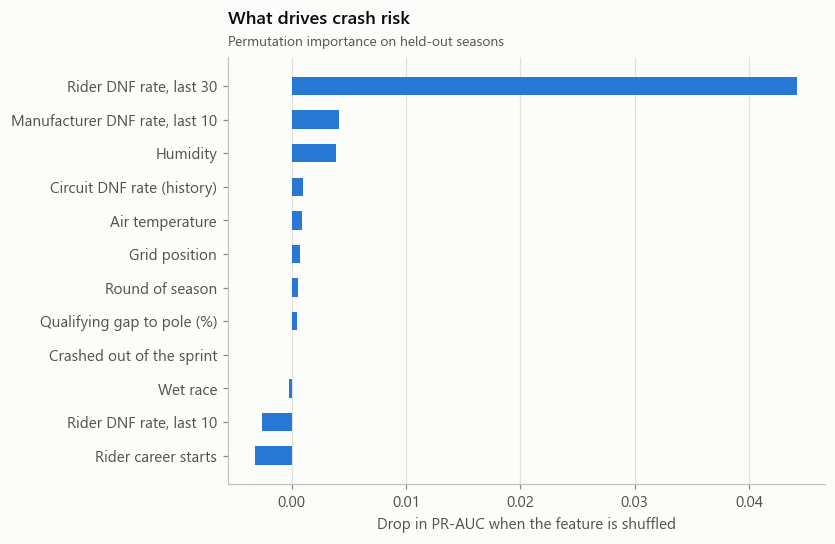

In [8]:
dclf = m.make_dnf_classifier().fit(train[DNF_FEATURES], train["dnf"])
dimp = m.permutation_importance_table(dclf, hold[DNF_FEATURES], hold["dnf"],
                                      scoring="average_precision")
dimp["label"] = dimp["feature"].map(FEATURE_LABELS)
dimp.to_csv(DATA_PROCESSED / "dnf_importance.csv", index=False)
fig = plots.importance(dimp, title="What drives crash risk", metric="PR-AUC")
plots.save(fig, "dnf_importance")
plt.show()

**Crash risk is close to unpredictable before the start.** The model beats the base rate, but
only by about as much as simply looking up the rider's own long-run DNF rate. That is a
finding in itself: once you know *who* is riding, most of the remaining crash risk is luck,
first-lap chaos and in-race decisions that no pre-race feature captures.

## Final models

Retrain both models on all races to date for the app.

In [9]:
bundle = m.train_final(df)
path = m.save_bundle(bundle)
print(f"Saved {path.name}: trained through {bundle['trained_through']} on {bundle['n_rows']:,} rows")

Saved motogp_models.joblib: trained through 2026-11-06 on 5,860 rows
